# Regresión Logistica


## Regresión Logística: Teoría y Práctica
 

### La regresión logística es un algoritmo de clasificación que modela la probabilidad de que una observación pertenezca a una categoría específica. A pesar de su nombre, es un método de **clasificación** no de regresión.

## Fundamentos Matemáticos

### La función sigmoide transforma valores reales en probabilidades entre 0 y 1:

 $$\sigma(z) = \frac{1}{1 + e^{-z}}$$
 
### donde 

$$z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p$$

### Formulaciones para el Modelo:
 
### Para clasificación binaria:
 
 $$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1x_1 + \cdots + \beta_px_p)}}$$

 $$P(Y=0|X) = 1 - P(Y=1|X)$$

### Función de Costo (Log Loss)
 
 $$J(\beta) = -\frac{1}{n}\sum_{i=1}^n [y_i\log(p_i) + (1-y_i)\log(1-p_i)]$$
 
### donde

$$p_i = P(Y=1|X_i)$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, auc, roc_auc_score, precision_recall_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

# Ejemplo 1:

## Queremos predecir si un estudiante aprueba ($y=1$) o reprueba ($y=0$) basado en:

## - $x_1$: Horas de estudio semanales

## - $x_2$: Promedio de calificaciones previas (escala 0-5)

In [4]:
np.random.seed(42)
plt.style.use('default')

print("=" * 60)
print("REGRESIÓN LOGÍSTICA: CLASIFICACIÓN DE ESTUDIANTES")
print("=" * 60)

# Datos de entrenamiento
datos = pd.DataFrame({
    'horas_estudio': [5, 3, 7, 2, 6, 4],
    'promedio_previo': [3.5, 2.8, 3.9, 2.5, 3.7, 3.0],
    'aprueba': [1, 0, 1, 0, 1, 0]
})

print("DATOS DE ENTRENAMIENTO:")
print(datos)

# Separar características y variable objetivo
X = datos[['horas_estudio', 'promedio_previo']].values
y = datos['aprueba'].values

print(f"\nMatriz de características X ({X.shape[0]} muestras, {X.shape[1]} características):")
print(X)
print(f"\nVector objetivo y: {y}")

REGRESIÓN LOGÍSTICA: CLASIFICACIÓN DE ESTUDIANTES
DATOS DE ENTRENAMIENTO:
   horas_estudio  promedio_previo  aprueba
0              5              3.5        1
1              3              2.8        0
2              7              3.9        1
3              2              2.5        0
4              6              3.7        1
5              4              3.0        0

Matriz de características X (6 muestras, 2 características):
[[5.  3.5]
 [3.  2.8]
 [7.  3.9]
 [2.  2.5]
 [6.  3.7]
 [4.  3. ]]

Vector objetivo y: [1 0 1 0 1 0]


### Vamos a desarrollar la implementación manual del modelo de regresión logística desde cero, utilizando el descenso de gradiente.

In [8]:
class RegresionLogisticaManual:
    """
    Implementación manual de regresión logística
    """
    
    def __init__(self, learning_rate=0.1, n_iteraciones=1000):
        self.learning_rate = learning_rate
        self.n_iteraciones = n_iteraciones
        self.beta = None  # Coeficientes [β₀, β₁, β₂]
        self.loss_history = []
        
    def sigmoide(self, z):
        """Función sigmoide: σ(z) = 1/(1+e^{-z})"""
        return 1 / (1 + np.exp(-z))
    
    def agregar_intercepto(self, X):
        """Agrega una columna de unos para el intercepto β₀"""
        n_samples = X.shape[0]
        return np.hstack([np.ones((n_samples, 1)), X])
    
    def loss_function(self, y, p):
        """Entropía cruzada: J(β) = -1/n Σ[y ln(p) + (1-y) ln(1-p)]"""
        epsilon = 1e-15  # Para evitar log(0)
        p = np.clip(p, epsilon, 1 - epsilon)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    
    def fit(self, X, y, verbose=True):
        """
        Entrena el modelo usando descenso de gradiente
        """
        # Agregar intercepto
        X_bias = self.agregar_intercepto(X)
        n_samples, n_features = X_bias.shape
        
        # Inicializar coeficientes
        self.beta = np.zeros(n_features)
        self.loss_history = []
        
        print("\n" + "=" * 50)
        print("ENTRENAMIENTO CON DESCENSO DE GRADIENTE")
        print("=" * 50)
        print(f"Tasa de aprendizaje: {self.learning_rate}")
        print(f"Número de iteraciones: {self.n_iteraciones}")
        
        for i in range(self.n_iteraciones):
            # Forward pass: calcular probabilidades
            z = X_bias.dot(self.beta)
            p = self.sigmoide(z)
            
            # Calcular pérdida
            loss = self.loss_function(y, p)
            self.loss_history.append(loss)
            
            # Calcular gradiente: ∇J = (1/n) X^T (p - y)
            gradiente = (1/n_samples) * X_bias.T.dot(p - y)
            
            # Actualizar coeficientes
            self.beta -= self.learning_rate * gradiente
            
            # Mostrar progreso
            if verbose and (i % 200 == 0 or i == self.n_iteraciones - 1):
                print(f"Iteración {i:4d}: Pérdida = {loss:.6f}")
        
        print(f"\nCoeficientes finales:")
        print(f"  β₀ (intercepto) = {self.beta[0]:.4f}")
        print(f"  β₁ (horas) = {self.beta[1]:.4f}")
        print(f"  β₂ (promedio) = {self.beta[2]:.4f}")
        
    def predict_proba(self, X):
        """Predice probabilidades P(y=1|x)"""
        X_bias = self.agregar_intercepto(X)
        z = X_bias.dot(self.beta)
        return self.sigmoide(z)
    
    def predict(self, X, threshold=0.5):
        """Predice clases (0 o 1) basado en un umbral"""
        proba = self.predict_proba(X)
        return (proba >= threshold).astype(int)


ENTRENAMIENTO CON DESCENSO DE GRADIENTE
Tasa de aprendizaje: 0.1
Número de iteraciones: 1000
Iteración    0: Pérdida = 0.693147
Iteración  200: Pérdida = 0.265878
Iteración  400: Pérdida = 0.204026
Iteración  600: Pérdida = 0.176124
Iteración  800: Pérdida = 0.158978
Iteración  999: Pérdida = 0.146866

Coeficientes finales:
  β₀ (intercepto) = -2.9487
  β₁ (horas) = 3.1812
  β₂ (promedio) = -3.4471


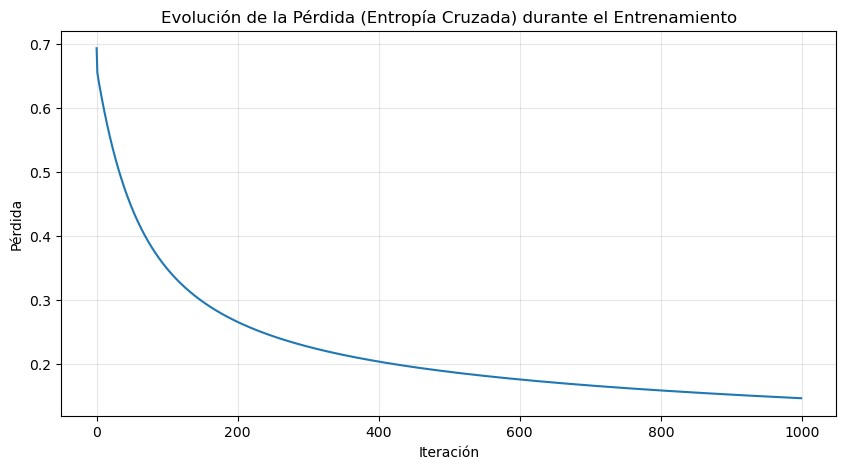

In [10]:
# Crear y entrenar el modelo
modelo_manual = RegresionLogisticaManual(learning_rate=0.1, n_iteraciones=1000)
modelo_manual.fit(X, y)


# Visualizar la evolución de la pérdida
plt.figure(figsize=(10, 5))
plt.plot(modelo_manual.loss_history)
plt.title('Evolución de la Pérdida (Entropía Cruzada) durante el Entrenamiento')
plt.xlabel('Iteración')
plt.ylabel('Pérdida')
plt.grid(True, alpha=0.3)
plt.show()

In [12]:
print("PREDICCIONES DEL MODELO MANUAL:")
print("=" * 50)

# Predicciones en los datos de entrenamiento
y_pred_manual = modelo_manual.predict(X)
y_proba_manual = modelo_manual.predict_proba(X)

for i, (x1, x2, y_real, y_pred, proba) in enumerate(zip(X[:,0], X[:,1], y, y_pred_manual, y_proba_manual)):
    print(f"Estudiante {i+1}:")
    print(f"  Horas: {x1}, Promedio: {x2}")
    print(f"  Real: {y_real}, Predicho: {y_pred}, Probabilidad: {proba:.4f}")
    print(f"  {'✓ Correcto' if y_real == y_pred else '✗ Incorrecto'}")
    print()

PREDICCIONES DEL MODELO MANUAL:
Estudiante 1:
  Horas: 5.0, Promedio: 3.5
  Real: 1, Predicho: 1, Probabilidad: 0.7094
  ✓ Correcto

Estudiante 2:
  Horas: 3.0, Promedio: 2.8
  Real: 0, Predicho: 0, Probabilidad: 0.0449
  ✓ Correcto

Estudiante 3:
  Horas: 7.0, Promedio: 3.9
  Real: 1, Predicho: 1, Probabilidad: 0.9972
  ✓ Correcto

Estudiante 4:
  Horas: 2.0, Promedio: 2.5
  Real: 0, Predicho: 0, Probabilidad: 0.0055
  ✓ Correcto

Estudiante 5:
  Horas: 6.0, Promedio: 3.7
  Real: 1, Predicho: 1, Probabilidad: 0.9672
  ✓ Correcto

Estudiante 6:
  Horas: 4.0, Promedio: 3.0
  Real: 0, Predicho: 0, Probabilidad: 0.3623
  ✓ Correcto



### Ya tenemos el modelo, ahora veamos una predicción para un nuevo estudiante que presenta 4 horas de estudio y  promedio 3.2

In [14]:
nuevo_estudiante = np.array([[4, 3.2]])
proba_nuevo = modelo_manual.predict_proba(nuevo_estudiante)[0]
pred_nuevo = modelo_manual.predict(nuevo_estudiante)[0]

print("PREDICCIÓN PARA NUEVO ESTUDIANTE:")
print("=" * 40)
print(f"Horas de estudio: 4")
print(f"Promedio previo: 3.2")
print(f"Probabilidad de aprobar: {proba_nuevo:.4f}")
print(f"Predicción: {'APRUEBA' if pred_nuevo == 1 else 'REPRUEBA'}")

PREDICCIÓN PARA NUEVO ESTUDIANTE:
Horas de estudio: 4
Promedio previo: 3.2
Probabilidad de aprobar: 0.2219
Predicción: REPRUEBA


## Ahora vamos a presentar otro ejemplo pero ahora con la función predeterminada de  scikit-learn

## Ejemplo 2:

## Vamos a desarrollar un caso de estudio simulado en el sector financiero, específicamente en la evaluación de riesgo crediticio. Este ejemplo simula un escenario real en el que una institución financiera necesita predecir la probabilidad de que un cliente incumpla con el pago de un crédito (default). El dataset generado incluye variables predictoras clave utilizadas en la industria, como:

### ingreso mensual

### score crediticio 

### nivel de endeudamiento

### antigüedad laboral

### historial crediticio, 

## Estas variables se relacionan mediante un modelo logístico subyacente que refleja las dinámicas reales de riesgo. La variable objetivo binaria (default/no default) se deriva de una función sigmoide que combina estas variables con un componente aleatorio, creando así un conjunto de datos realista pero controlado que permite demostrar de manera efectiva todo el flujo de trabajo de la regresión logística, desde el preprocesamiento hasta la evaluación del modelo.


### Matemáticamente, la variable objetivo (default) se genera mediante un proceso que simula el comportamiento subyacente de un modelo logístico real. Primero, se calcula un score lineal combinando las variables predictoras:

$$
z = -5 + 0.0005 \times \text{ingreso\_mensual} - 0.02 \times \text{score\_credito} + 0.0001 \times \text{deuda\_total} - 0.3 \times \text{antiguedad\_empleo} 
$$

$$+ 0.001 \times \text{ratio\_deuda\_ingreso} \times 1000 - 0.2 \times \text{historial\_crediticio} + \varepsilon$$

### donde 
$$\varepsilon \sim N(0,1)$$

### representa el ruido aleatorio. Este score $z$ se transforma luego en probabilidades mediante la función sigmoide:

$$
P(\text{default} = 1) = \frac{1}{1 + e^{-z}}
$$

### Finalmente, la variable binaria default se determina aplicando un umbral de 0.5:

$$
\text{default} = \begin{cases} 
1 & \text{si } P(\text{default} = 1) > 0.5 \\
0 & \text{en caso contrario}
\end{cases}
$$

### replicando así el proceso de decisión que seguiría un modelo de riesgo crediticio en condiciones reales.

In [34]:
# A continuación se generan los datos de ejemplo para predicción de riesgo crediticio

def generar_datos_crediticios(n_samples=1000):
    """
    Genera datos simulados para predecir riesgo de default crediticio
    """
    np.random.seed(42)
    
    # Variables predictoras
    ingreso_mensual = np.random.normal(5000, 2000, n_samples)
    score_credito = np.random.normal(650, 100, n_samples)
    deuda_total = np.random.normal(15000, 8000, n_samples)
    antiguedad_empleo = np.random.exponential(3, n_samples)
    edad = np.random.randint(18, 70, n_samples)
    ratio_deuda_ingreso = deuda_total / (ingreso_mensual + 1)
    historial_crediticio = np.random.exponential(5, n_samples)
    
# Crear variable objetivo (default) con relaciones realistas
    
    z = (
        -5 + 
        0.0005 * ingreso_mensual - 
        0.02 * score_credito + 
        0.0001 * deuda_total - 
        0.3 * antiguedad_empleo + 
        0.001 * ratio_deuda_ingreso * 1000 -
        0.2 * historial_crediticio +
        np.random.normal(0, 1, n_samples)
    )
    
    probabilidad_default = 1 / (1 + np.exp(-z))
    default = (probabilidad_default > 0.5).astype(int)
    
# Crear DataFrame
    
    data = pd.DataFrame({
        'default': default,
        'ingreso_mensual': ingreso_mensual,
        'score_credito': score_credito,
        'deuda_total': deuda_total,
        'antiguedad_empleo': antiguedad_empleo,
        'edad': edad,
        'ratio_deuda_ingreso': ratio_deuda_ingreso,
        'historial_crediticio': historial_crediticio,
        'probabilidad_real': probabilidad_default
    })
    
    return data

Dimensión del dataset: (1000, 9)

Distribución de la variable objetivo:
default
0    990
1     10
Name: count, dtype: int64

Primeras 5 filas:
Estadísticas descriptivas:
           default  ingreso_mensual  score_credito   deuda_total  \
count  1000.000000      1000.000000    1000.000000   1000.000000   
mean      0.010000      5038.664112     657.083624  15046.673716   
std       0.099549      1958.431876      99.745438   7867.634249   
min       0.000000     -1482.534680     355.961137  -9156.097247   
25%       0.000000      3704.819389     589.375831   9816.003090   
50%       0.000000      5050.601224     656.307713  14997.993881   
75%       0.000000      6295.887751     722.888218  20287.322515   
max       1.000000     12705.462981     969.310757  46409.901651   

       antiguedad_empleo         edad  ratio_deuda_ingreso  \
count        1000.000000  1000.000000          1000.000000   
mean            2.902112    42.767000             4.142772   
std             2.927742    14.

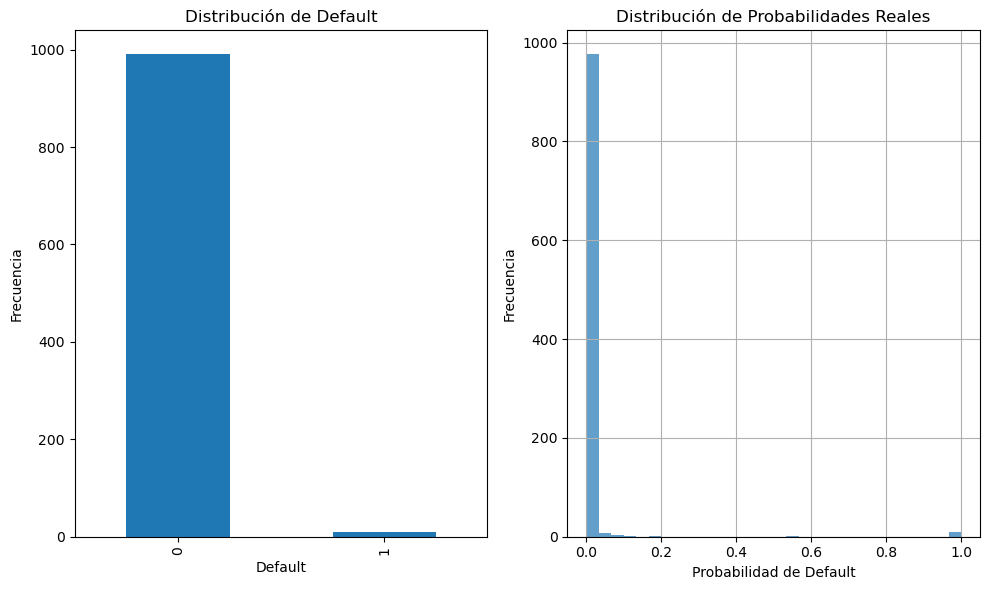

In [36]:
# Generar datos

df_credito = generar_datos_crediticios(1000)
print("Dimensión del dataset:", df_credito.shape)
print("\nDistribución de la variable objetivo:")
print(df_credito['default'].value_counts())
print("\nPrimeras 5 filas:")
df_credito.head()


# Análisis exploratorio de datos

print("Estadísticas descriptivas:")
print(df_credito.describe())

# Distribución de la variable objetivo

plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
df_credito['default'].value_counts().plot(kind='bar')
plt.title('Distribución de Default')
plt.xlabel('Default')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
df_credito['probabilidad_real'].hist(bins=30, alpha=0.7)
plt.title('Distribución de Probabilidades Reales')
plt.xlabel('Probabilidad de Default')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

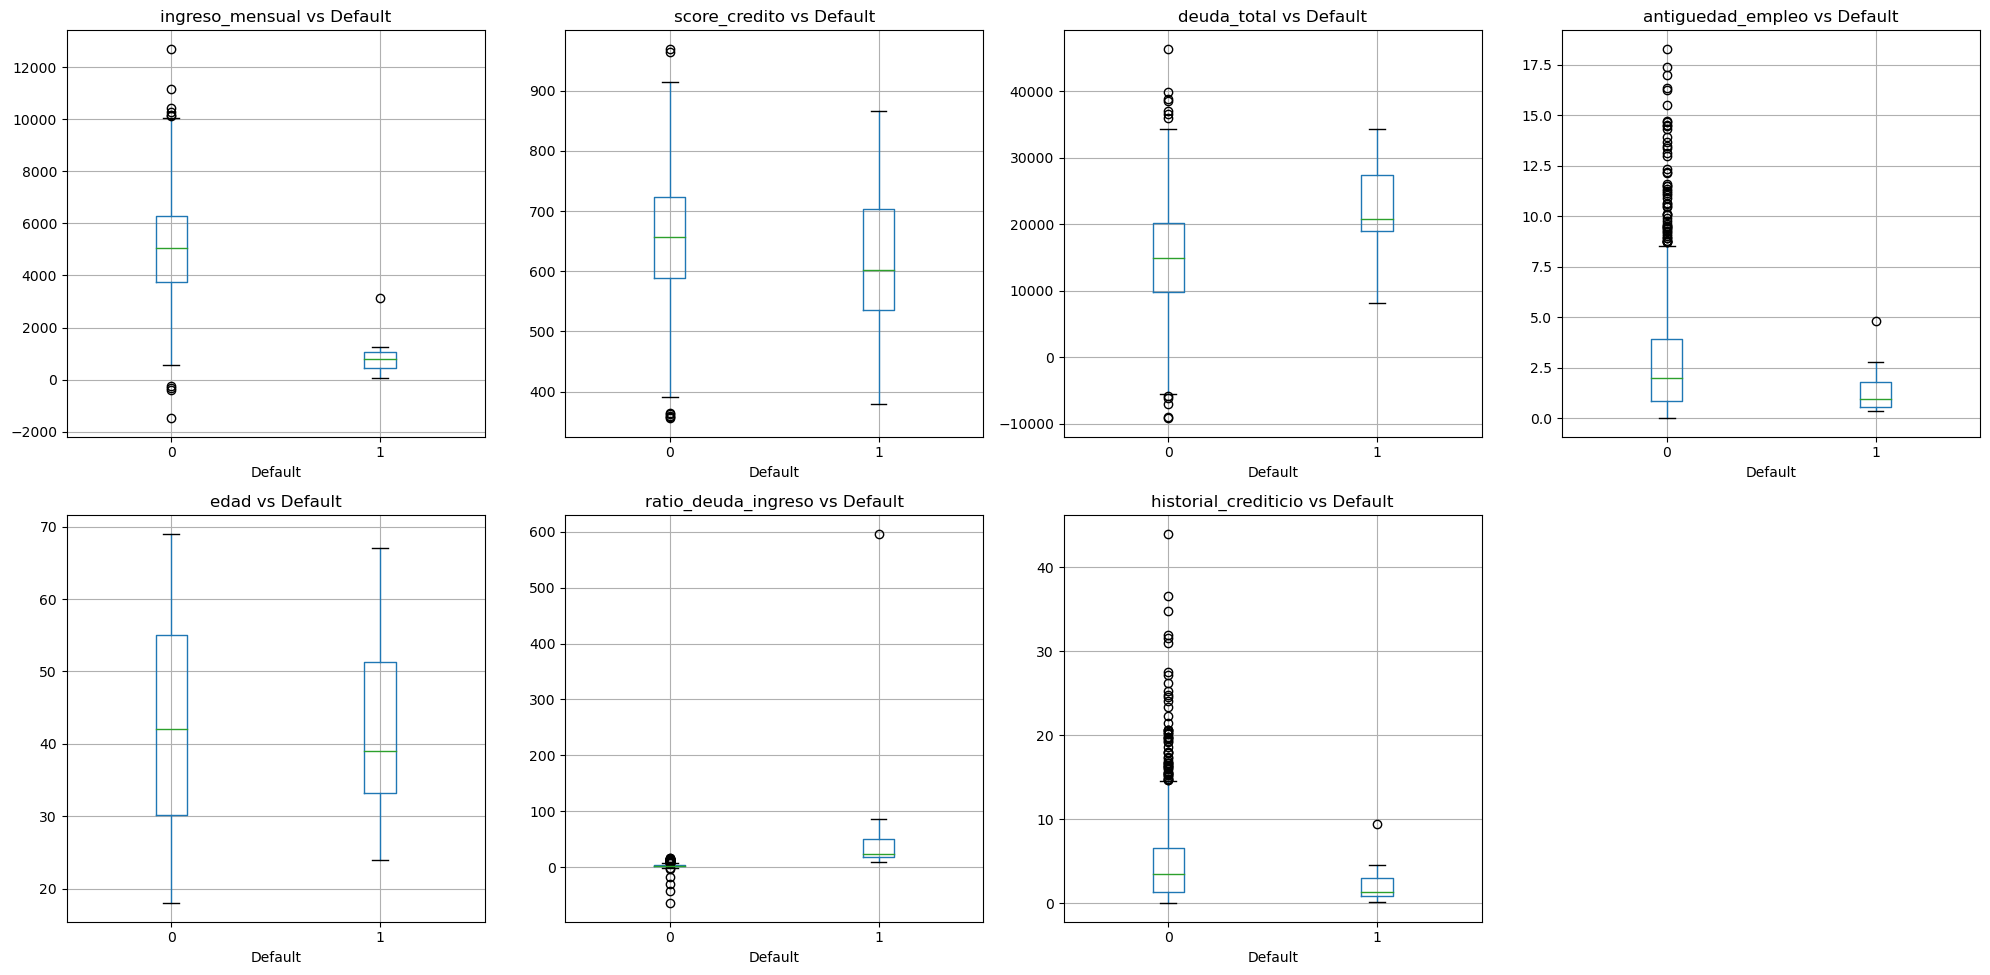

In [38]:
# Relaciones entre variables y la variable objetivo

variables_numericas = ['ingreso_mensual', 'score_credito', 'deuda_total', 
                      'antiguedad_empleo', 'edad', 'ratio_deuda_ingreso', 'historial_crediticio']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, var in enumerate(variables_numericas):
    # Boxplot por categoría de default
    df_credito.boxplot(column=var, by='default', ax=axes[i])
    axes[i].set_title(f'{var} vs Default')
    axes[i].set_xlabel('Default')

# Ocultar eje extra

axes[-1].set_visible(False)
plt.suptitle('')
plt.tight_layout()
plt.show()

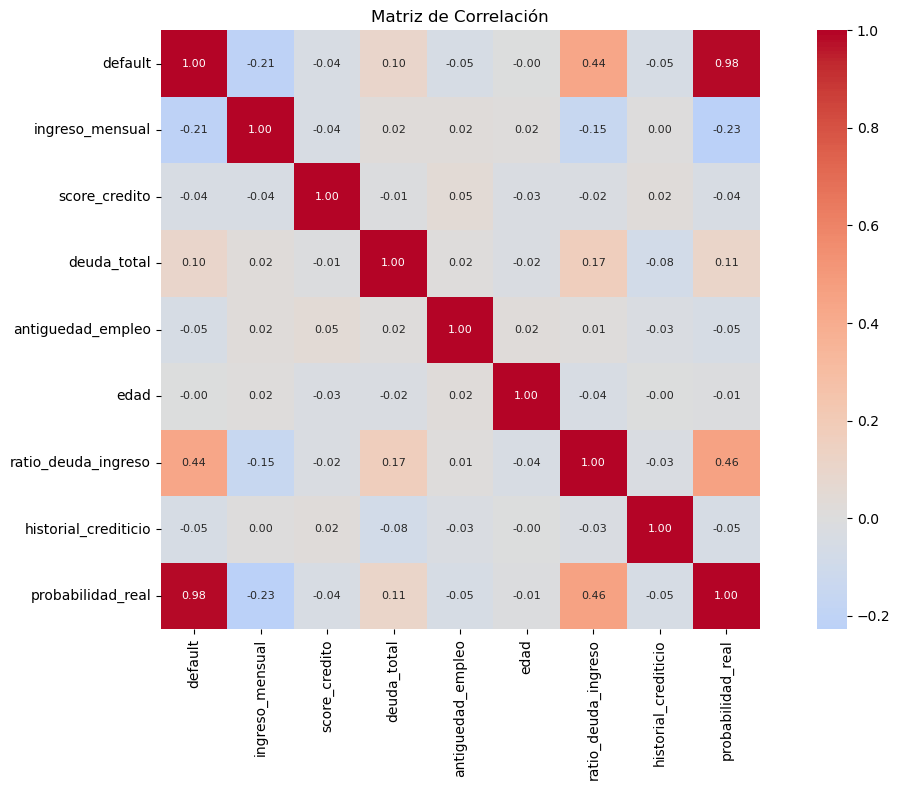

In [40]:
# Matriz de correlación

plt.figure(figsize=(12, 8))
correlation_matrix = df_credito.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Matriz de Correlación')
plt.tight_layout()
plt.show()

In [42]:
# Preparación de datos para el modelo

X = df_credito.drop(['default', 'probabilidad_real'], axis=1)
y = df_credito['default']

# Dividir en conjunto de entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Escalar variables (importante para regresión logística)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Tamaño conjunto de entrenamiento: {X_train.shape}")
print(f"Tamaño conjunto de prueba: {X_test.shape}")
print(f"Proporción de default en entrenamiento: {y_train.mean():.3f}")
print(f"Proporción de default en prueba: {y_test.mean():.3f}")

Tamaño conjunto de entrenamiento: (700, 7)
Tamaño conjunto de prueba: (300, 7)
Proporción de default en entrenamiento: 0.010
Proporción de default en prueba: 0.010


In [44]:
# Entrenamiento del modelo de regresión logística

modelo_logistico = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced'  # Para manejar desbalance de clases
)

modelo_logistico.fit(X_train_scaled, y_train)

# Coeficientes del modelo

coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo_logistico.coef_[0],
    'Odds_Ratio': np.exp(modelo_logistico.coef_[0]),
    'Abs_Coef': np.abs(modelo_logistico.coef_[0])
}).sort_values('Abs_Coef', ascending=False)

print("Coeficientes del modelo de regresión logística:")
print(coeficientes.to_string(index=False))
print(f"\nIntercepto: {modelo_logistico.intercept_[0]:.4f}")

Coeficientes del modelo de regresión logística:
            Variable  Coeficiente  Odds_Ratio  Abs_Coef
 ratio_deuda_ingreso     3.704085   40.612885  3.704085
     ingreso_mensual    -3.163116    0.042294  3.163116
   antiguedad_empleo    -1.510024    0.220905  1.510024
historial_crediticio    -1.432007    0.238829  1.432007
         deuda_total     1.300855    3.672435  1.300855
       score_credito    -0.926370    0.395988  0.926370
                edad     0.366023    1.441988  0.366023

Intercepto: -8.2396


In [46]:
# Predicciones y evaluación

y_pred = modelo_logistico.predict(X_test_scaled)
y_pred_proba = modelo_logistico.predict_proba(X_test_scaled)[:, 1]  # Probabilidades para clase 1

# Métricas de evaluación

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred_proba)

print("Métricas de evaluación del modelo:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"AUC-ROC: {auc_score:.4f}")

Métricas de evaluación del modelo:
Accuracy: 0.9767
Precision: 0.3000
Recall: 1.0000
F1-Score: 0.4615
AUC-ROC: 1.0000


Text(120.72222222222221, 0.5, 'Real')

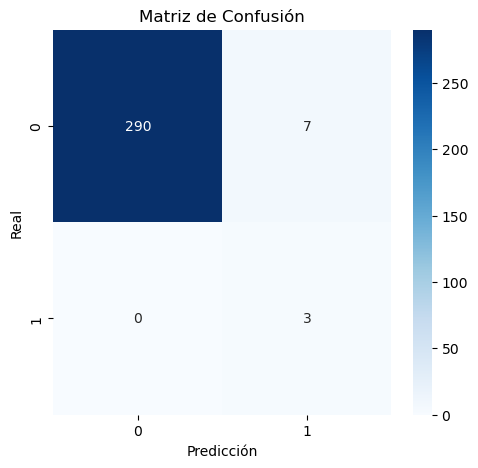

In [48]:
# Matriz de confusión

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')

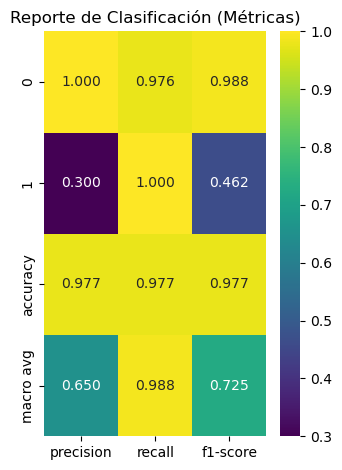

Reporte de clasificación detallado:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       297
           1       0.30      1.00      0.46         3

    accuracy                           0.98       300
   macro avg       0.65      0.99      0.72       300
weighted avg       0.99      0.98      0.98       300



In [50]:
# Reporte de clasificación

plt.subplot(1, 2, 2)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='viridis', fmt='.3f')
plt.title('Reporte de Clasificación (Métricas)')
plt.tight_layout()
plt.show()

print("Reporte de clasificación detallado:")
print(classification_report(y_test, y_pred))

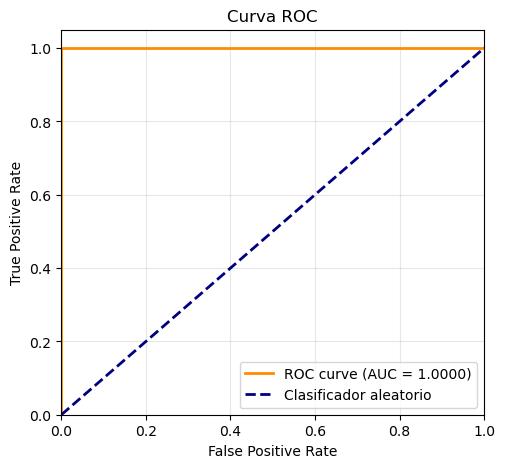

In [52]:
# Curva ROC y AUC

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Clasificador aleatorio')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

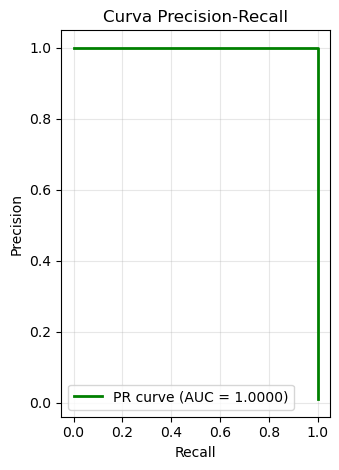

In [54]:
# Curva Precision-Recall

plt.subplot(1, 2, 2)
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall_vals, precision_vals)

plt.plot(recall_vals, precision_vals, color='green', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

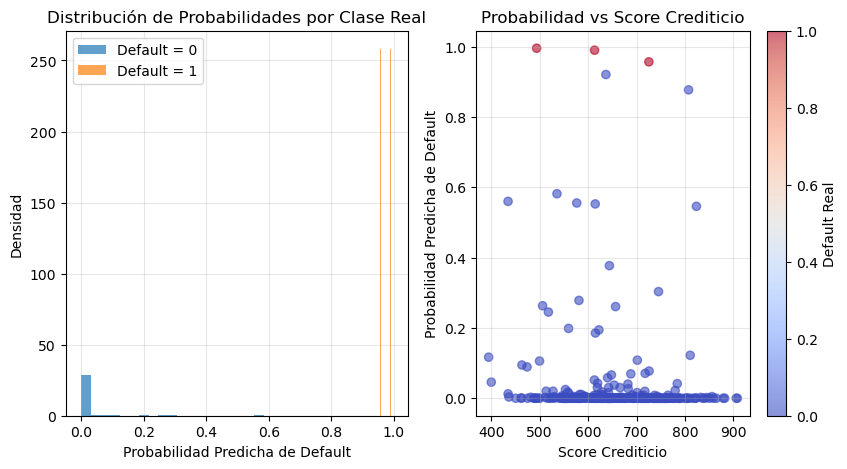

In [56]:
# Análisis de probabilidades predichas

plt.figure(figsize=(15, 5))

# Distribución de probabilidades por clase real

plt.subplot(1, 3, 1)
for clase in [0, 1]:
    plt.hist(y_pred_proba[y_test == clase], bins=30, alpha=0.7, 
             label=f'Default = {clase}', density=True)
plt.xlabel('Probabilidad Predicha de Default')
plt.ylabel('Densidad')
plt.title('Distribución de Probabilidades por Clase Real')
plt.legend()
plt.grid(True, alpha=0.3)

# Relación entre probabilidad predicha y score crédito

plt.subplot(1, 3, 2)
plt.scatter(X_test['score_credito'], y_pred_proba, c=y_test, cmap='coolwarm', alpha=0.6)
plt.xlabel('Score Crediticio')
plt.ylabel('Probabilidad Predicha de Default')
plt.title('Probabilidad vs Score Crediticio')
plt.colorbar(label='Default Real')
plt.grid(True, alpha=0.3)

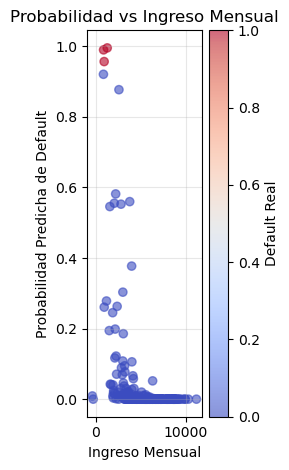

INTERPRETACIÓN DE ODDS RATIOS:
ratio_deuda_ingreso: Odds Ratio = 40.6129 (Aumenta probabilidad de default)
ingreso_mensual: Odds Ratio = 0.0423 (Disminuye probabilidad de default)
antiguedad_empleo: Odds Ratio = 0.2209 (Disminuye probabilidad de default)
historial_crediticio: Odds Ratio = 0.2388 (Disminuye probabilidad de default)
deuda_total: Odds Ratio = 3.6724 (Aumenta probabilidad de default)
score_credito: Odds Ratio = 0.3960 (Disminuye probabilidad de default)
edad: Odds Ratio = 1.4420 (Aumenta probabilidad de default)


In [58]:
# Relación entre probabilidad predicha e ingreso mensual

plt.subplot(1, 3, 3)
plt.scatter(X_test['ingreso_mensual'], y_pred_proba, c=y_test, cmap='coolwarm', alpha=0.6)
plt.xlabel('Ingreso Mensual')
plt.ylabel('Probabilidad Predicha de Default')
plt.title('Probabilidad vs Ingreso Mensual')
plt.colorbar(label='Default Real')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Interpretación de odds ratios

print("INTERPRETACIÓN DE ODDS RATIOS:")
print("=" * 50)
for _, row in coeficientes.iterrows():
    if row['Variable'] != 'intercept':
        interpretacion = f"{row['Variable']}: Odds Ratio = {row['Odds_Ratio']:.4f}"
        if row['Odds_Ratio'] > 1:
            interpretacion += f" (Aumenta probabilidad de default)"
        else:
            interpretacion += f" (Disminuye probabilidad de default)"
        print(interpretacion)

In [60]:
# Ejemplo de cálculo de probabilidad para un caso específico

print("\nEJEMPLO DE CÁLCULO DE PROBABILIDAD:")
print("=" * 50)

# Caso de ejemplo
caso_ejemplo = X.iloc[0:1].copy()
caso_escalado = scaler.transform(caso_ejemplo)

probabilidad = modelo_logistico.predict_proba(caso_escalado)[0, 1]
print(f"Probabilidad de default para el caso ejemplo: {probabilidad:.4f}")

# Contribución de cada variable

z = modelo_logistico.intercept_[0] + np.sum(modelo_logistico.coef_[0] * caso_escalado)
print(f"Valor z (log-odds): {z:.4f}")
print(f"Odds: {np.exp(z):.4f}")


EJEMPLO DE CÁLCULO DE PROBABILIDAD:
Probabilidad de default para el caso ejemplo: 0.0000
Valor z (log-odds): -13.8137
Odds: 0.0000


In [62]:
#Validación cruzada CORREGIDA

from sklearn.model_selection import StratifiedKFold

# Usar StratifiedKFold para mantener la proporción de clases en cada fold
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(modelo_logistico, X_train_scaled, y_train, 
                           cv=cv_stratified, scoring='accuracy')

print("Validación Cruzada (5-fold estratificado):")
print(f"Accuracy promedio: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")

# También calcular otras métricas en validación cruzada

scoring_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results = {}
for metric in scoring_metrics:
    scores = cross_val_score(modelo_logistico, X_train_scaled, y_train, 
                            cv=cv_stratified, scoring=metric)
    cv_results[metric] = {
        'mean': scores.mean(),
        'std': scores.std(),
        'scores': scores
    }

print("\nResultados de Validación Cruzada por Métrica:")
for metric, results in cv_results.items():
    print(f"{metric}: {results['mean']:.4f} (±{results['std']:.4f})")

# Verificar distribución de clases en los folds

print("\nDistribución de clases en cada fold:")
for fold_idx, (train_idx, val_idx) in enumerate(cv_stratified.split(X_train_scaled, y_train)):
    y_val_fold = y_train.iloc[val_idx]
    print(f"Fold {fold_idx + 1}: Clase 0 = {sum(y_val_fold == 0)}, Clase 1 = {sum(y_val_fold == 1)}")

Validación Cruzada (5-fold estratificado):
Accuracy promedio: 0.9757 (±0.0097)

Resultados de Validación Cruzada por Métrica:
accuracy: 0.9757 (±0.0097)
precision: 0.3071 (±0.1108)
recall: 0.9000 (±0.2000)
f1: 0.4260 (±0.0796)
roc_auc: 0.9986 (±0.0029)

Distribución de clases en cada fold:
Fold 1: Clase 0 = 139, Clase 1 = 1
Fold 2: Clase 0 = 139, Clase 1 = 1
Fold 3: Clase 0 = 139, Clase 1 = 1
Fold 4: Clase 0 = 138, Clase 1 = 2
Fold 5: Clase 0 = 138, Clase 1 = 2


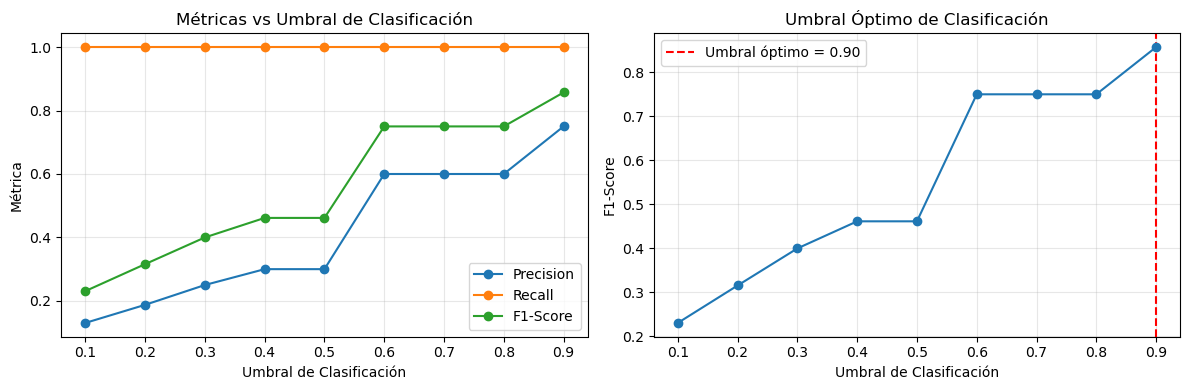

Umbral óptimo: 0.90


In [64]:
# Ajuste de umbral de clasificación

umbrales = np.linspace(0.1, 0.9, 9)
resultados_umbral = []

for umbral in umbrales:
    y_pred_umbral = (y_pred_proba >= umbral).astype(int)
    precision = precision_score(y_test, y_pred_umbral)
    recall = recall_score(y_test, y_pred_umbral)
    f1 = f1_score(y_test, y_pred_umbral)
    
    resultados_umbral.append({
        'umbral': umbral,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

df_umbrales = pd.DataFrame(resultados_umbral)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(df_umbrales['umbral'], df_umbrales['precision'], 'o-', label='Precision')
plt.plot(df_umbrales['umbral'], df_umbrales['recall'], 'o-', label='Recall')
plt.plot(df_umbrales['umbral'], df_umbrales['f1'], 'o-', label='F1-Score')
plt.xlabel('Umbral de Clasificación')
plt.ylabel('Métrica')
plt.title('Métricas vs Umbral de Clasificación')
plt.legend()
plt.grid(True, alpha=0.3)

# Umbral óptimo (maximizando F1-score)
umbral_optimo = df_umbrales.loc[df_umbrales['f1'].idxmax(), 'umbral']
plt.subplot(1, 2, 2)
plt.axvline(x=umbral_optimo, color='red', linestyle='--', label=f'Umbral óptimo = {umbral_optimo:.2f}')
plt.plot(df_umbrales['umbral'], df_umbrales['f1'], 'o-')
plt.xlabel('Umbral de Clasificación')
plt.ylabel('F1-Score')
plt.title('Umbral Óptimo de Clasificación')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Umbral óptimo: {umbral_optimo:.2f}")

In [66]:
# Modelo con umbral óptimo

y_pred_optimo = (y_pred_proba >= umbral_optimo).astype(int)

print("Comparación con umbral óptimo vs umbral default (0.5):")
print(f"Accuracy (umbral 0.5): {accuracy_score(y_test, y_pred):.4f}")
print(f"Accuracy (umbral óptimo): {accuracy_score(y_test, y_pred_optimo):.4f}")
print(f"F1-Score (umbral 0.5): {f1_score(y_test, y_pred):.4f}")
print(f"F1-Score (umbral óptimo): {f1_score(y_test, y_pred_optimo):.4f}")

Comparación con umbral óptimo vs umbral default (0.5):
Accuracy (umbral 0.5): 0.9767
Accuracy (umbral óptimo): 0.9967
F1-Score (umbral 0.5): 0.4615
F1-Score (umbral óptimo): 0.8571


# TAREA 6

## Regrese este notebook incluyendo los siguientes puntos desarrollados:

## 1. Desarrolle el ejemplo 2 a mano, tal cual como se hizo con el ejemplo 1 en clase.

## 2. Haga todos los comentarios que hacen falta a lo largo del ejemplo 2, para que sea entendible.

## 3. Repita el ejemplo 1 utilizando como modelo la función predeterminada de scikit-learn, compare el resultado con las funciones creadas para el ejemplo 1.